> **Isolation for Multi-agent**

In [52]:
import os
from dotenv import load_dotenv
from rich.console import Console
from utils import format_messages
from rich.markdown import Markdown
from IPython.display import display, Markdown

console = Console()
load_dotenv()

True

In [1]:
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
from langgraph_supervisor import create_supervisor

In [12]:
def _set_env(var : str) -> None:
    """
    Set environment variable if not alread set.
    """
    if not os.environ.get(var):
        raise EnvironmentError(f"{var} not found.!!")


_set_env("GOOGLE_API_KEY")

llm = init_chat_model(
    "gemini-3.1-flash-lite",
    model_provider = "google_genai",
    timeout        = 60,
    max_retries    = 5,
    temperature    = 0,
)

In [13]:
def add(a: float, b: float) -> float:
    """Add two numbers.
    
    Args:
        a: First number
        b: Second number
        
    Returns:
        Sum of a and b
    """
    return a + b


def multiply(a: float, b: float) -> float:
    """Multiply two numbers.
    
    Args:
        a: First number
        b: Second number
        
    Returns:
        Product of a and b
    """
    return a * b


def web_search(query: str) -> str:
    """Mock web search function that returns FAANG company headcounts.
    
    Args:
        query: Search query (unused in this mock)
        
    Returns:
        Static information about FAANG company headcounts
    """
    return (
        "Here are the headcounts for each of the FAANG companies in 2024:\n"
        "1. **Facebook (Meta)**: 67,317 employees.\n"
        "2. **Apple**: 164,000 employees.\n"
        "3. **Amazon**: 1,551,000 employees.\n"
        "4. **Netflix**: 14,000 employees.\n"
        "5. **Google (Alphabet)**: 181,269 employees."
    )

- **`Specialized agents with isolated context.`**

In [14]:
MathAgent = create_agent(
    model         = llm,
    tools         = [add, multiply],
    name          = "Math Professor",
    system_prompt = "You are a math expert. Always use one tool at a time."
)

ResearchAgent = create_agent(
    model         = llm,
    tools         = [web_search],
    name          = "Research Expert",
    system_prompt = "You are a world class researcher with access to web search. Do not do any math."
)

workflow = create_supervisor(
    [ResearchAgent, MathAgent],
    model = llm,
    prompt = (
        "You are a team supervisor managing a research expert and a math expert. "
        "For current events, use research_agent. "
        "For math problems, use math_agent."
    )
)

## Compile multi-agent application
app = workflow.compile()

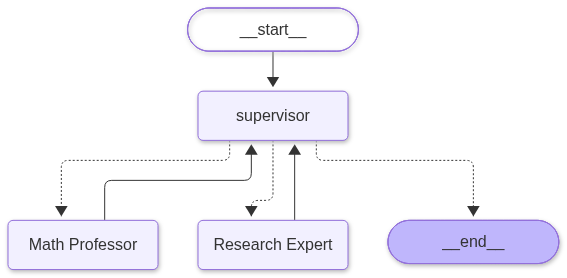

In [15]:
app

In [16]:
result = app.invoke(
    {
        'messages' : [
            {
                'role' : 'user',
                'content' : "What is the combined headcount of the FAANG comapnies in 2024 ?"
            }
        ]
    }
)
console.print("[bold green]▣ Received response from multi-agent application.[/bold green]")


▣ Received response from multi-agent application.

In [21]:
format_messages(result['messages'])

┌───────────────────────────────── 🧑 Human ──────────────────────────────────┐
│ What is the combined headcount of the FAANG comapnies in 2024 ?             │
└─────────────────────────────────────────────────────────────────────────────┘
┌─────────────────────────────────── 📝 AI ───────────────────────────────────┐
│                                                                             │
└─────────────────────────────────────────────────────────────────────────────┘
┌────────────────────────────── 🔧 Tool Output ───────────────────────────────┐
│ Successfully transferred to Research Expert                                 │
└─────────────────────────────────────────────────────────────────────────────┘
┌─────────────────────────────────── 📝 AI ───────────────────────────────────┐
│ To determine the combined headcount of the FAANG companies in 2024, we look │
│ at the most recent figures reported by each company:                        │
│                                           

In [54]:
for res_obj in result['messages']:

    content = res_obj.text

    if not content:
        continue

    res_obj_type = res_obj.type.upper()
    res_obj_name = res_obj.name or res_obj_type

    display(Markdown(f"### {res_obj_name}"))
    display(Markdown(content))
    display(Markdown("---"))

### HUMAN

What is the combined headcount of the FAANG comapnies in 2024 ?

---

### transfer_to_research_expert

Successfully transferred to Research Expert

---

... (8 outputs left out)

---

### supervisor

The combined headcount of the FAANG companies (Meta, Apple, Amazon, Netflix, and Alphabet) as of their most recent 2024 reports is approximately **1,977,586**.

Here is the breakdown by company:

*   **Amazon:** 1,551,000
*   **Alphabet (Google):** 181,269
*   **Apple:** 164,000
*   **Meta (Facebook):** 67,317
*   **Netflix:** 14,000

---

In [50]:
result['messages']

[HumanMessage(content='What is the combined headcount of the FAANG comapnies in 2024 ?', additional_kwargs={}, response_metadata={}, id='8fe4e5ae-5827-4f83-9b71-a7ef085c9055'),
 AIMessage(content=[], additional_kwargs={'function_call': {'name': 'transfer_to_research_expert', 'arguments': '{"question": "What is the combined headcount of the FAANG companies (Meta, Amazon, Apple, Netflix, Alphabet/Google) as of their most recent 2024 reports?"}'}, '__gemini_function_call_thought_signatures__': {'call_13784228000267428447': 'EqkBCqYBAWkUfRPo2uk8AsgEVANlTx24U1gxXSvmLYK37VqrGj+Murat5TjdPfe5xwEt9Cv9IO70FS2dxWgOLbR8Fr37g2awKaVcCmfP+xflZDBK03cLGPdIFm7cKKeBVTYp2Cht/kcKvmNhjVcr+tj5BeAUW7p9kfBXY/S9rfJiTflxDD+f4EkIAFtPS9gEBwev+UN3ThQgIKl7KI55lIm8CEcKUUd+qNCctQ=='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.1-flash-lite', 'safety_ratings': [], 'normalized_finish_reason': 'tool_call', 'model_provider': 'google_genai'}, name='supervisor', id='lc_run--01a21245-2b32-7ac0-9aa3-